# Code examples for plotting the gamma-ray flux

In [1]:
from mario.gamma.flux import GammaFlux, HadronicGammaMaker

In [2]:
import astropy.units as u
import numpy as np
import matplotlib.pyplot as plt
from astropy.wcs import WCS
from astropy.io import fits

In [3]:
from mario.sources import Accelerator
G8 = Accelerator(name='SNR G8.7-0.1', 
                 glon=8.744205*u.deg, glat=-0.096288*u.deg, radius=0.375*u.deg,
                 age=15*u.kyr, distance=4.5*u.kpc, gas_mass=7.9e5*u.solMass)

In [4]:
from mario.gas_utilities import GasParameters, calc_average_number_density, calc_n0
gas = '/home/kirsty/Documents/PhD/Fits_Files/Models/total_col_dens_30_40.fits'
gp = GasParameters(acc=G8, gas_map_path=gas)

In [5]:
pdf_cube_path = 'HadronicPDF_HadronicImpulsiveTime_chi0.01_delta0.6_D03e+27_n15_n00.029_ESN1e+51_Mej20.0_Epmax1.0t_sedov2850.88_deltap2.5.fits'
f = fits.open(pdf_cube_path)
header = f[0].header

## Plot gamma flux at energy

In [6]:
maker = HadronicGammaMaker(pdf_cube_path=pdf_cube_path, acc=G8, gp=gp, alpha=2, eta=0.1)

In [7]:
from mario.plotting import set_limits

glon_limit = [7.4, 9.5]
glat_limit = [-0.5, 0.5]

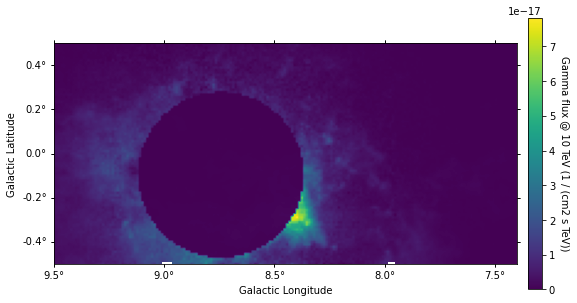

In [8]:
ax = maker.plot_gamma_flux(Egamma=10*u.TeV, cmap='viridis')
set_limits(ax, maker.gp.header, l=glon_limit, b=glat_limit)

## Plot integral gamma-ray flux

In [13]:
from mario.plotting import add_gamma_src

src_fits = 'data/hgps_map_flux_0.1deg_v1_crop.fits'
con_levels = [2e-13, 3e-13, 4e-13, 5e-13, 5.8e-13]
year = '2018'

In [14]:
Egmin = 1*u.TeV
Egmax = 100*u.TeV

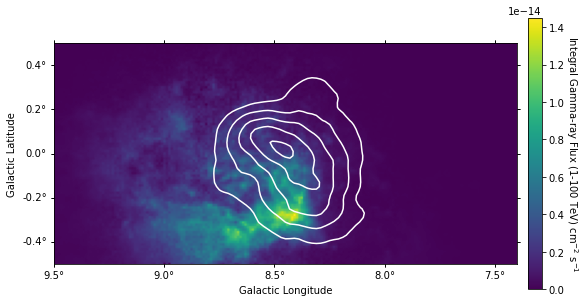

In [15]:
ax = maker.plot_gamma_integral_flux(Egmin, Egmax)
set_limits(ax, maker.gp.header, l=glon_limit, b=glat_limit)
add_gamma_src(ax, src_fits, con_levels, year, colors='white')

## Plot oversampled integral flux

In [16]:
from mario.plotting import add_SNR

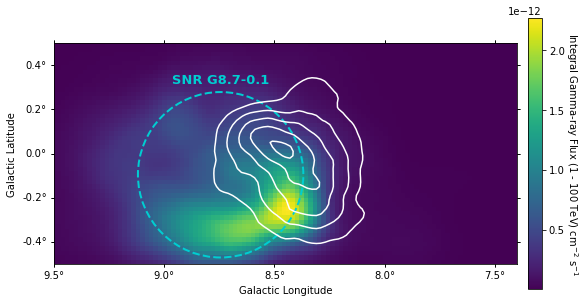

In [17]:
ax = maker.plot_oversample_gamma_integral_flux(Egmin, Egmax, grid_size=0.02*u.deg, radius=0.1*u.deg)
set_limits(ax, maker.oversampled_header, l=glon_limit, b=glat_limit)
add_SNR(G8, ax, facecolor='None', edgecolor='#00CED1', ls='--', lw=2)
add_gamma_src(ax, src_fits, con_levels, year, colors='white')

## Plot the gamma-ray spectra

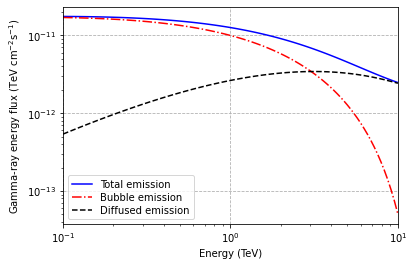

In [18]:
maker.plot_gamma_spectra('e2dnde', 0.1*u.TeV, 10*u.TeV,
                         8.2*u.deg, 0.01*u.deg, 0.5*u.deg, 'galactic')

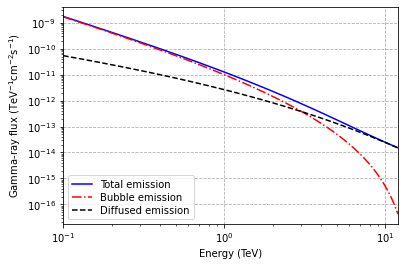

In [19]:
maker.plot_gamma_spectra('dnde', 0.1*u.TeV, 12*u.TeV,
                         8.2*u.deg, 0.01*u.deg, 0.5*u.deg, 'galactic')

## Save gamma-ray flux cube
### Chosen eta value

In [20]:
E1 = np.logspace(-2, 0, 100)[:-1]*u.TeV
E2 = np.logspace(0, 2, 100)*u.TeV
Egamma = np.concatenate((E1, E2))

gf = GammaFlux(acc=G8, pdf_cube_path=pdf_cube_path, gp=gp, 
               alpha=2, eta=0.01, 
              xsection='Kafexhiu')
gf.flux(Egamma)

In [21]:
extra_comments = {'HGAM_SRC':header['HGAM_SRC'],
                  'HACC':header['HACC'],
                  'HENERGY1':'np.logspace(-2, 0, 100)[:-1]*u.TeV',
                  'HENERGY2':'np.logspace(0, 2, 100)*u.TeV'}
gf.save(author='Kirsty Feijen', extra_comments=extra_comments)

### Eta value to match observations
Load in observations

In [22]:
fermi_spectra = np.loadtxt('data/Fermi_spectra_data.csv', delimiter=',', skiprows=1)
E_Fermi = fermi_spectra[:,0] * u.TeV
Flux_Fermi = fermi_spectra[:,1] * 1/(u.TeV*u.cm**2*u.s)

hess_spectra = np.loadtxt('data/HESS_spectra_data.csv', delimiter=',', skiprows=1)
E_HESS = hess_spectra[:,0] * u.TeV
Flux_HESS = hess_spectra[:,1] * 1/(u.TeV*u.cm**2*u.s)

Calculate flux based on the energy from observations

In [23]:
E = np.concatenate((E_Fermi.to(u.TeV), E_HESS.to(u.TeV)))
gf_initial = GammaFlux(acc=G8, pdf_cube_path=pdf_cube_path, gp=gp, 
                       alpha=2, eta=1, 
                       xsection='Kafexhiu')

gf_initial.flux(E)
extra_comments = {'HGAM_SRC':header['HGAM_SRC'],
                  'HACC':header['HACC']}
cube_header = gf_initial.save_header(extra_comments=extra_comments)
data = gf_initial.fluxes.value

In [24]:
from mario.sources import GammaSource
hess = GammaSource(name='HESS J1804', spectral_index=2.69, 
                   glon=8.4*u.deg, glat=-0.03*u.deg, radius=0.367*u.deg, 
                   flux_GeV=1.56e-9 / (u.s * u.cm**2),
                   flux_E_GeV=0.01 * u.TeV,
                   flux_TeV=5.32e-11/(u.s * u.cm**2),
                   flux_E_TeV=0.2 * u.TeV)

Calculate eta value from observations

In [25]:
from mario.gamma.spatialmodel import SpatialModel3D
sm3D = SpatialModel3D(data, cube_header, energies=E)   
e, F_model = sm3D.sum_region(coords=[hess.glon, hess.glat], radius=hess.radius)

F = np.concatenate((Flux_Fermi, Flux_HESS))

factor = np.linspace(0.0001, 1, 100000)
residual = []
for f in factor:
    residual += [np.nansum(np.abs(F.value - f * F_model))]
eta = factor[np.argmin(residual)] 

Calculate gamma flux with new eta and save

In [26]:
E1 = np.logspace(-2, 0, 100)[:-1]*u.TeV
E2 = np.logspace(0, 2, 100)*u.TeV
Egamma = np.concatenate((E1, E2))

gf2 = GammaFlux(acc=G8, pdf_cube_path=pdf_cube_path, gp=gp, 
               alpha=2, eta=eta, 
              xsection='Kafexhiu')
gf2.flux(Egamma)

In [27]:
extra_comments = {'HGAM_SRC':header['HGAM_SRC'],
                  'HACC':header['HACC'],
                  'HENERGY1':'np.logspace(-2, 0, 100)[:-1]*u.TeV',
                  'HENERGY2':'np.logspace(0, 2, 100)*u.TeV'}
gf2.save(author='Kirsty Feijen', extra_comments=extra_comments)